<a href="https://colab.research.google.com/github/tfunck/hacking_hour/blob/main/BigBrain_Section_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
print("Hello world!")

Hello world!


In [6]:
# Import all required libraries
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage.filters import threshold_otsu
from skimage import exposure
import requests
from tqdm import tqdm

# Function to download files with a progress bar
def download_file(url, dest_path):
    """Download a file from a URL to a destination path with a progress bar."""
    if not os.path.exists(dest_path):
        response = requests.get(url, stream=True)
        total = int(response.headers.get('content-length', 0))
        with open(dest_path, 'wb') as file, tqdm(
            desc=f"Downloading {os.path.basename(dest_path)}",
            total=total, unit='iB', unit_scale=True
        ) as bar:
            for data in response.iter_content(chunk_size=1024):
                size = file.write(data)
                bar.update(size)
    else:
        print(f"{os.path.basename(dest_path)} already exists.")

  # Create a directory for storing data
data_dir = "bigbrain_data"
os.makedirs(data_dir, exist_ok=True)

# URLs of the BigBrain volume and segmentation
volume_url = "https://ftp.bigbrainproject.org/bigbrain-ftp/BigBrainRelease.2015/3D_Volumes/MNI-ICBM152_Space/nii/full8_400um_2009b_sym.nii.gz"
seg_url = "https://ftp.bigbrainproject.org/bigbrain-ftp/BigBrainRelease.2015/3D_Classified_Volumes/MNI-ICBM152_Space/nii/full_cls_400um_2009b_sym.nii.gz"

# Paths to save the files locally
volume_path = os.path.join(data_dir, "full8_400um_2009b_sym.nii.gz")
seg_path = os.path.join(data_dir, "full_cls_400um_2009b_sym.nii.gz")

# Download the files
download_file(volume_url, volume_path)
download_file(seg_url, seg_path)



full8_400um_2009b_sym.nii.gz already exists.
full_cls_400um_2009b_sym.nii.gz already exists.


In [7]:
# Load the NIfTI images using nibabel
img = nib.load(volume_path)
seg = nib.load(seg_path)

# Extract the image data as numpy arrays
img_data = img.get_fdata()
seg_data = seg.get_fdata()

img_data = img_data.max() - img_data

# Print shape to understand dimensions (should be 3D)
print("Histology Image shape:", img_data.shape)
print("Segmentation shape:", seg_data.shape)


Histology Image shape: (493, 583, 473)
Segmentation shape: (493, 583, 473)


In [ ]:
print()

[0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360, 390, 420, 450, 480, 510, 540, 570]


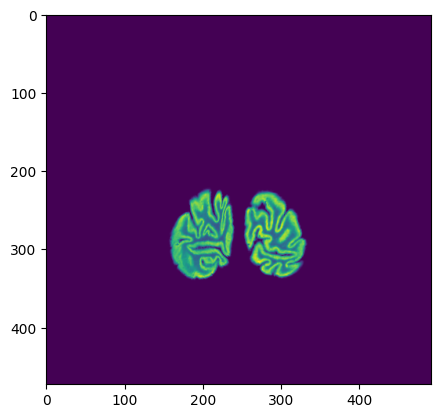

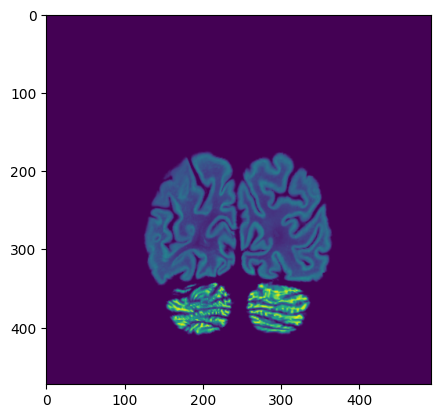

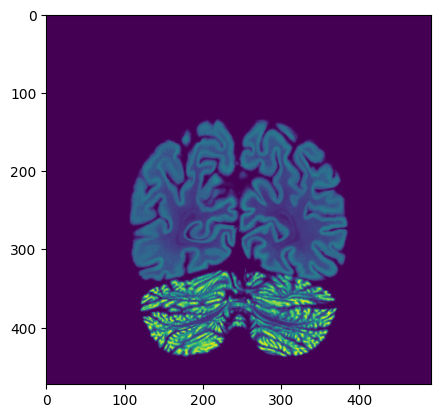

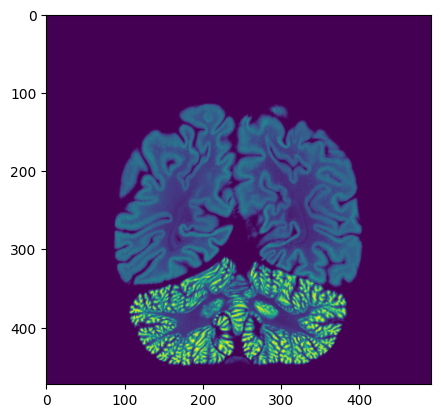

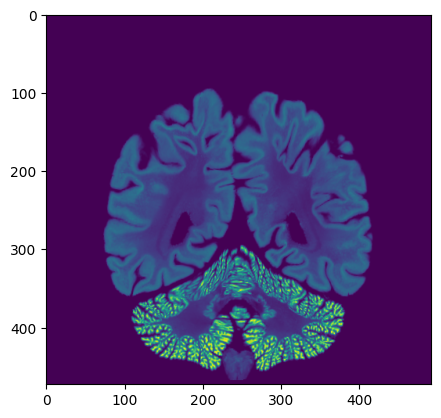

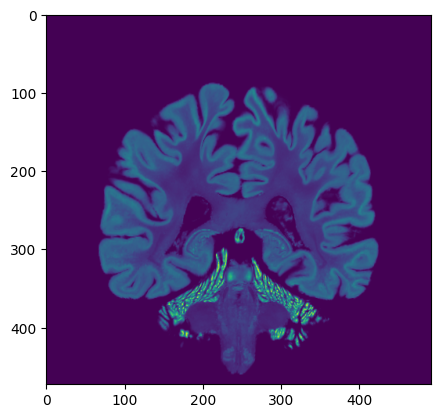

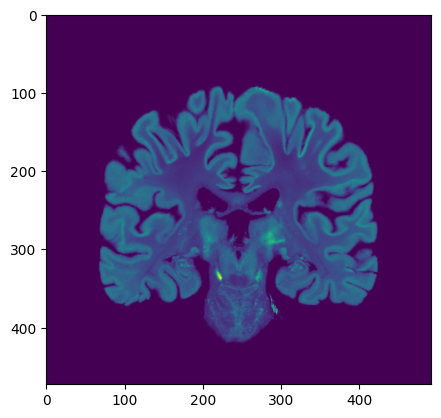

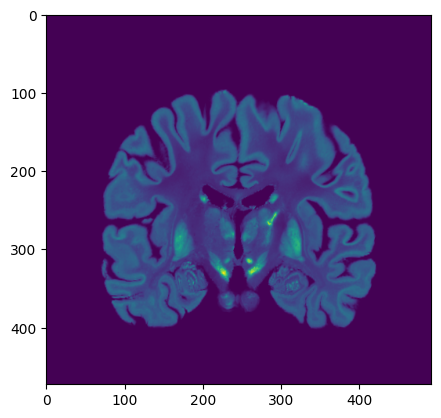

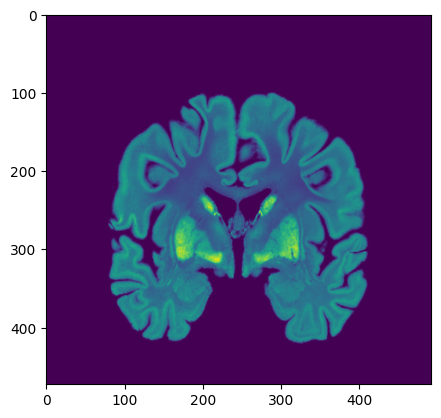

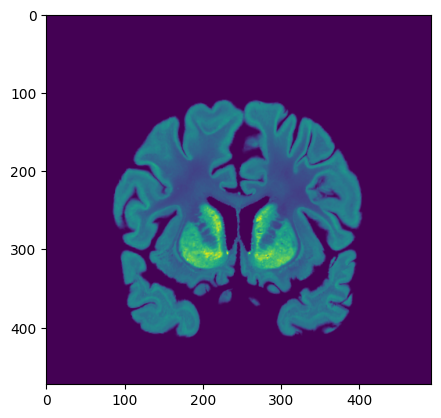

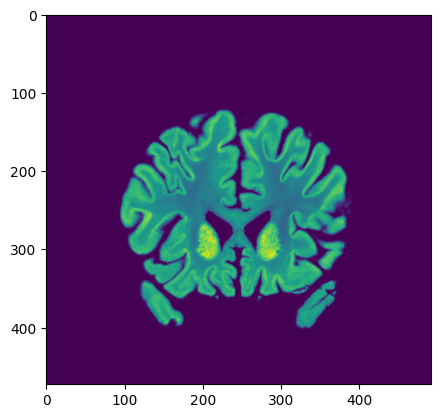

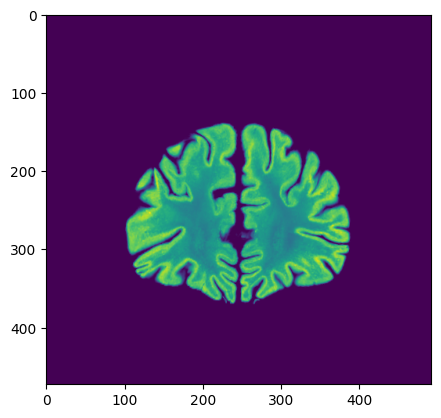

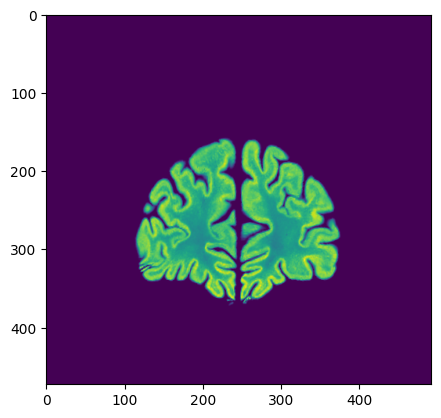

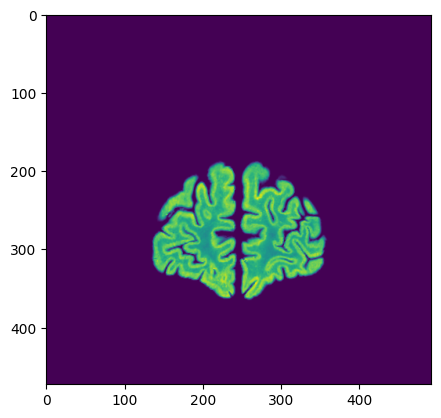

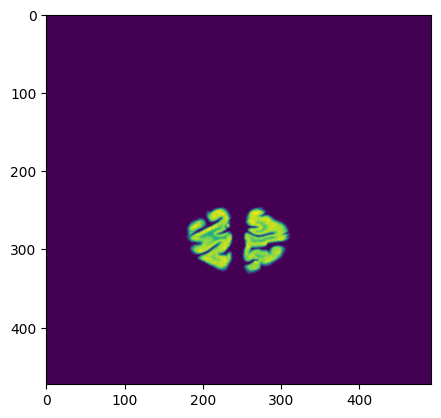

Hello!


In [36]:
# Dimensions: 0-->x 1-->y  2-->z

# Write some code that will display all the sections in the y axis for the image volume
ydim = img_data.shape[1]

list_of_y_indices = range(0,ydim,30)

print(list(list_of_y_indices))

sections_list = []
list_of_good_y_indices = []

for y in list_of_y_indices :
  section = np.rot90(img_data[:,y,:])
  # plotting code

  if np.sum(section) > 0 :
    sections_list.append(section)

    list_of_good_y_indices.append(y)

    plt.imshow(section)
    plt.show()




print('Hello!')

In [40]:
def kmeans_segmentation(section):

  flat_img = section.ravel().reshape(-1, 1)

  image_min = np.min(flat_img)
  image_mean = np.mean(flat_img)
  image_max = np.max(flat_img)

  init = np.array([image_min, image_mean, image_max]).reshape(-1,1)
  init = np.array([[image_min], [image_mean], [image_max]])

  # Apply KMeans clustering to group pixels into 3 clusters
  kmeans_obj = KMeans(n_clusters=3, init=init, random_state=42)
  kmeans = kmeans_obj.fit(flat_img)

  # Reshape labels back into image shape
  kmeans_mask = kmeans.labels_.reshape(section.shape)

  return kmeans_mask

kmeans_seg_list = []

for section in sections_list :
  seg = kmeans_segmentation(section)
  kmeans_seg_list.append(seg)


In [54]:
a_list = ['a', 'b', 'c']
b_list = [1, 2, 3]
c_list = [np.mean, np.min, np.max]

for a, b, c in zip(a_list, b_list, c_list) :
  print("", a, b,c)

 a 1 <function mean at 0x7faeb7d360c0>
 b 2 <function min at 0x7faeb7d35800>
 c 3 <function max at 0x7faeb7d356c0>


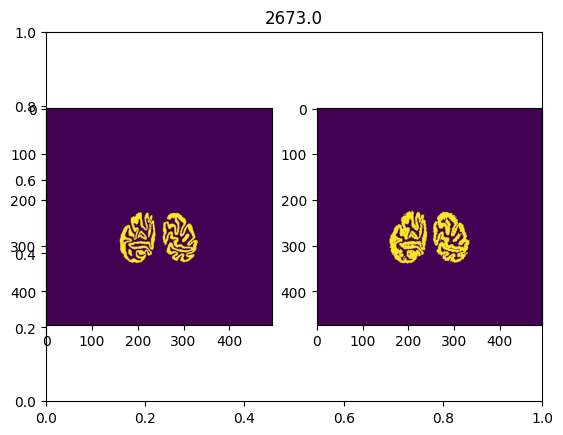

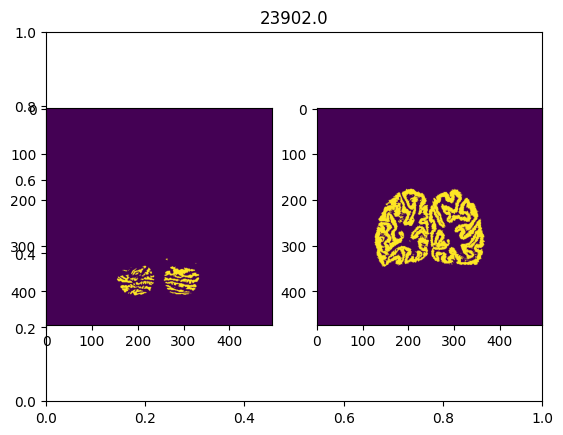

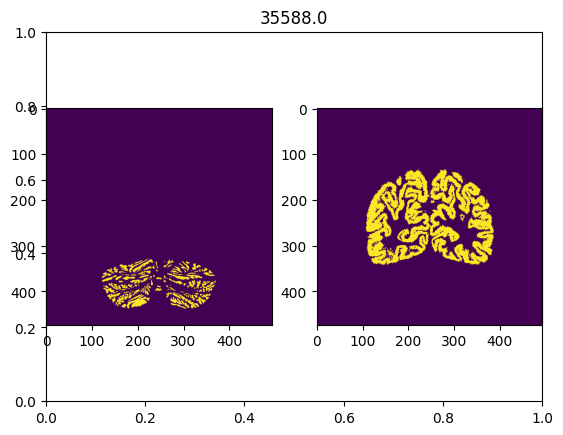

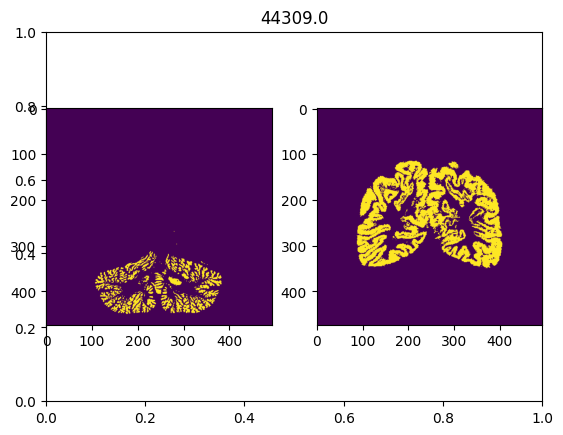

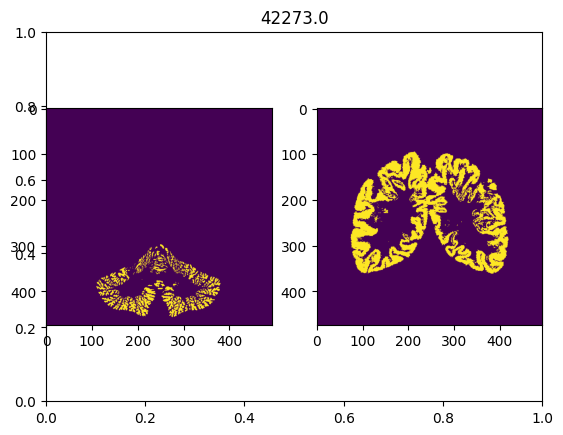

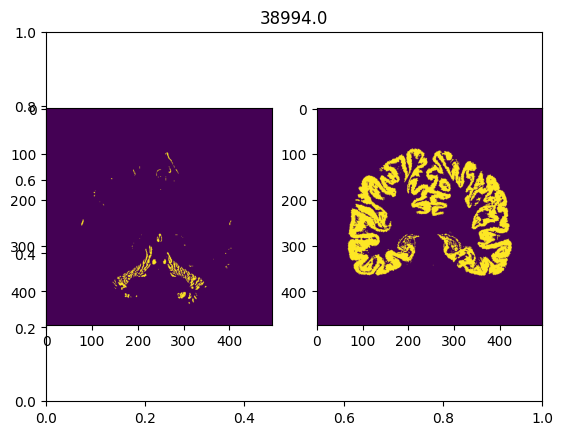

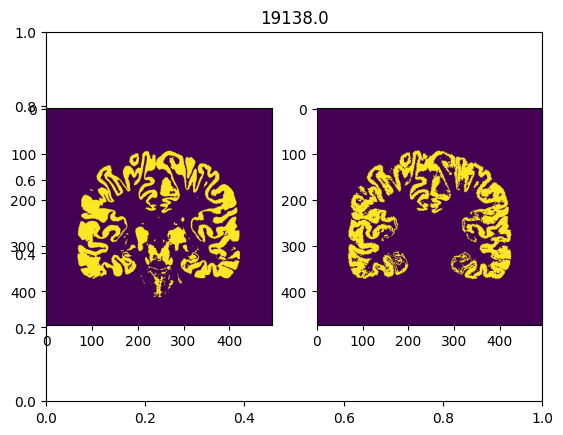

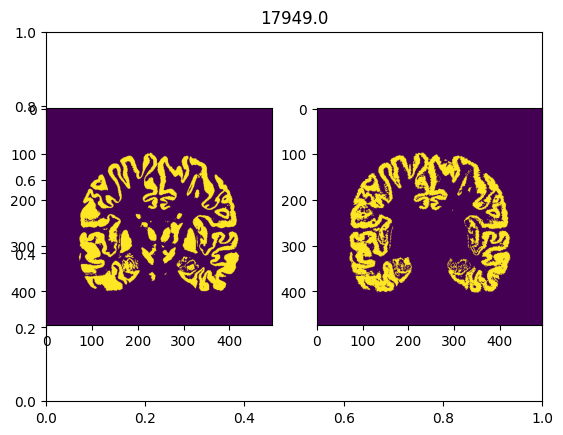

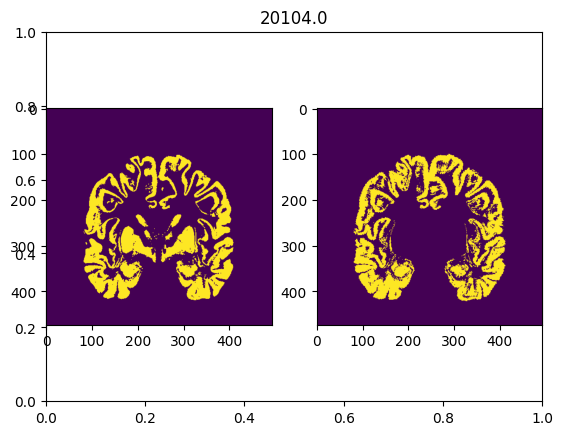

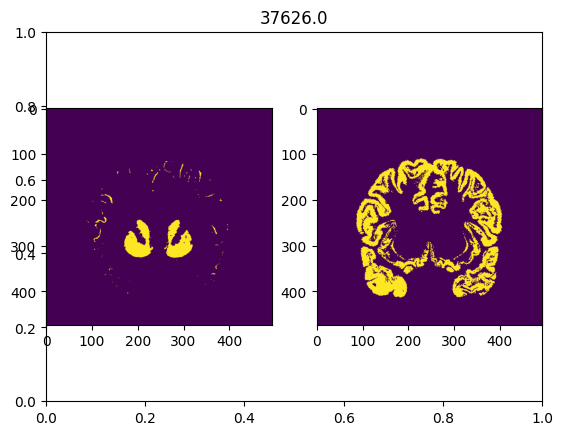

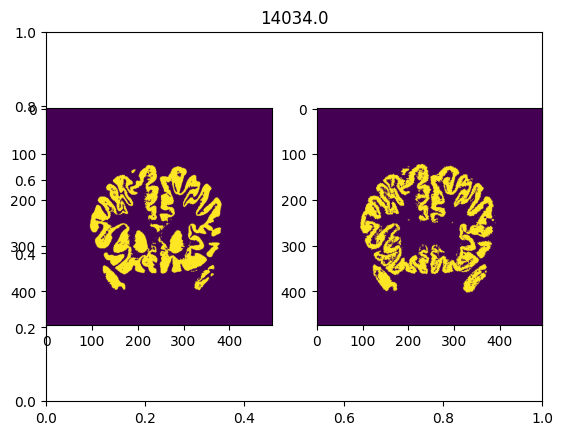

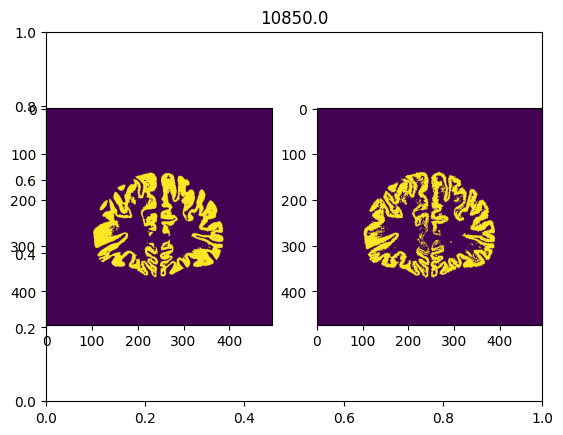

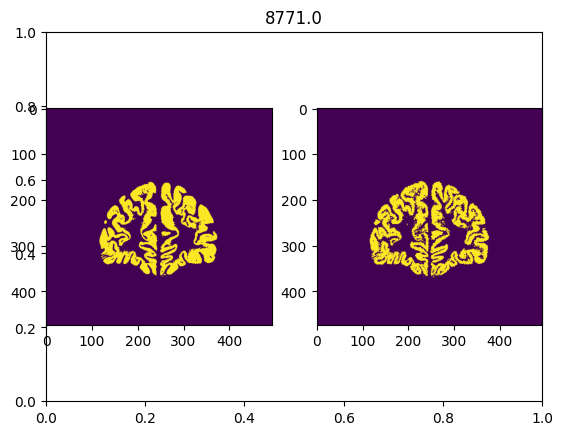

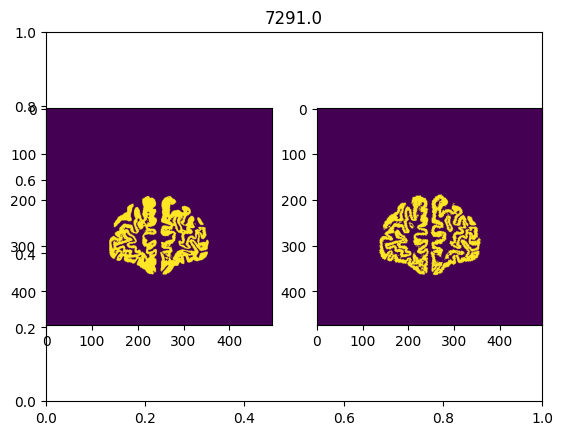

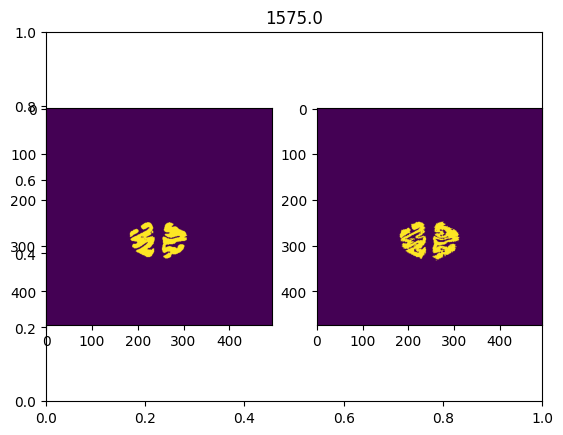

In [57]:

def compare_segmentations(x, y):
  # Try to implement the Dice Score

  metric = np.sum(np.pow(x-y,2))

  return metric

metric_list = []

# We iterate over two lists at the same time.
# kmeans_seg is a numpy array that comes from kmeans_seg_list
# y is a integer that comes from list_of_good_y_indices
for kmeans_seg, y in zip(kmeans_seg_list, list_of_good_y_indices):

  # We're getting a section, y, from the ground truth segmentation volume seg_data
  # We also rotate by 90 degrees so that it's oriented correctly for imshow
  seg = np.rot90(seg_data[:,y,:])

  # We want to create an image that only contains the GM
  # So first we create an empty (i.e., every element equals 0) array
  seg_gm = np.zeros(seg.shape)

  # THen for all pixels in our seg section that are equal to 5 or 2, we set seg_gm equal 1
  seg_gm[(seg==5) | (seg==2)] = 1

  # Same thing here, we want to create an image with only GM from our kmeans segmentation
  # So we create an empty numpy array
  kmeans_gm = np.zeros(kmeans_seg.shape)
  # And then for all pixels/elements equal to 2 in kmeans_seg, we set kmeans_gm equal to 1
  kmeans_gm[ kmeans_seg == 2] = 1

  metric = compare_segmentations(kmeans_gm, seg_gm)
  metric_list.append(metric)

  plt.title(metric)
  plt.subplot(1,2,1)
  plt.imshow(kmeans_gm)

  plt.subplot(1,2,2)
  plt.imshow(seg_gm)
  plt.show()


[np.float64(2673.0), np.float64(23902.0), np.float64(35588.0), np.float64(44309.0), np.float64(42273.0), np.float64(38994.0), np.float64(19138.0), np.float64(17949.0), np.float64(20104.0), np.float64(37626.0), np.float64(14034.0), np.float64(10850.0), np.float64(8771.0), np.float64(7291.0), np.float64(1575.0)]


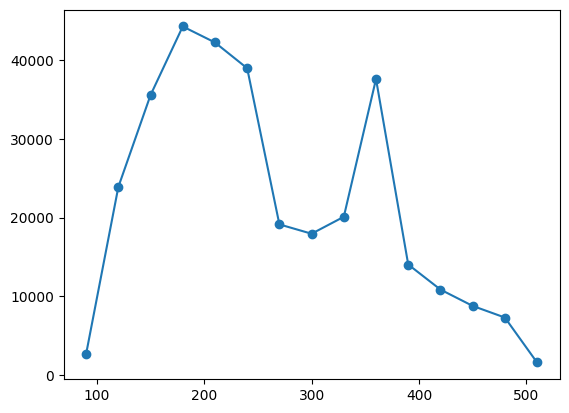

In [60]:
print(metric_list)

plt.plot(list_of_good_y_indices, metric_list )
plt.scatter(list_of_good_y_indices, metric_list )
plt.show()